# Tugas Take-Home Sesi 05 — Advanced CNNs and Transfer Learning

**Nama / NIM:** Alexandria Natasya Beslar / 2802471801
**Dataset:** Oxford-IIIT Pet, subset 10 kelas (5 kucing + 5 anjing)  
**Arsitektur:** ResNet-18 (utama) dan EfficientNet-B0 (B5, bonus)  
**Platform:** Google Colab, GPU T4

## Daftar isi
1. Setup lingkungan dan reproduksibilitas
2. Data: pemilihan 10 kelas dan split stratified 70/15/15
3. Transform, Dataset, DataLoader (augmentasi hanya untuk train)
4. Mesin training: logger, model B1/B2/B3/B5, fungsi training, verifikasi
5. Menjalankan eksperimen (B1, B2, B3, B4, seed 42/43/44)
6. Konsolidasi hasil (C1): tabel dan kurva loss
7. Analisis B4: efek augmentasi
8. B5: arsitektur pembanding
9. Failure analysis (C3)
10. Grad-CAM sebelum vs sesudah fine-tuning (C5, opsional)
11. Penutup dan daftar artefak

## Catatan penting
- Semua angka pada laporan harus berasal dari file di `Tugas05/logs/` (CSV dan JSON yang dibuat otomatis oleh notebook ini).
- Jika notebook dijalankan ulang, angka bisa bergeser sedikit karena GPU tidak sepenuhnya deterministik. Pastikan angka di laporan berasal dari **eksekusi final** notebook ini.
- Bantuan AI pada kode dijelaskan pada AI Disclosure Statement di laporan.

## 1. Setup lingkungan dan reproduksibilitas

**Tujuan:** menyiapkan folder kerja di Google Drive, semua library, seed tetap, dan mencatat versi library.

**Mengapa penting:**
- Folder log di Drive bertahan walau runtime Colab putus.
- Seed tetap dan versi library tercatat adalah syarat reproduksibilitas (protokol 4.2 dan rubrik kriteria 5).
- `requirements.txt` dibuat otomatis dari versi yang benar-benar dipakai, sehingga cocok dengan hasil eksperimen.

**Cek:** output `Device: cuda`. Jika `cpu`, aktifkan GPU dulu.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = '/content/drive/MyDrive/Tugas05'
for d in ['logs', 'figures', 'checkpoints']:
    os.makedirs(f'{BASE}/{d}', exist_ok=True)
print('Folder kerja:', BASE)

Mounted at /content/drive
Folder kerja: /content/drive/MyDrive/Tugas05


In [5]:
import random, json, time, copy, glob, re, sys, platform
from collections import Counter
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report

SEED = 42
SEEDS = [42, 43, 44]


def set_seed(seed=SEED):
    """Mengunci seed Python, NumPy, dan PyTorch (CPU + GPU)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type != 'cuda':
    print('PERINGATAN: GPU belum aktif. Runtime -> Change runtime type -> T4 GPU')

# Catat lingkungan dan buat requirements.txt dari versi yang benar-benar dipakai
PKGS = ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'Pillow']
env = {
    'python': sys.version.split()[0],
    'platform': platform.platform(),
    'seed': SEED,
    'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'cpu',
    'packages': {p: version(p).split('+')[0] for p in PKGS},
}
with open(f'{BASE}/logs/env.json', 'w') as f:
    json.dump(env, f, indent=2)
with open(f'{BASE}/requirements.txt', 'w') as f:
    f.write('\n'.join(f'{p}=={v}' for p, v in env['packages'].items()) + '\n')
print(json.dumps(env, indent=2))

Device: cuda
{
  "python": "3.13.15",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "seed": 42,
  "gpu": "Tesla T4",
  "packages": {
    "torch": "2.11.0",
    "torchvision": "0.26.0",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "Pillow": "11.3.0"
  }
}


## 2. Data: pemilihan 10 kelas dan split stratified

### 2.1 Unduh dan gabungkan `trainval` + `test`
Split bawaan torchvision hanya memberi ±100 gambar per kelas pada `trainval`. Soal meminta ±200 gambar per kelas lalu split sendiri 70/15/15, jadi kedua split bawaan digabung dulu.

**Cek:** `37 7349` (37 kelas, 7.349 gambar).

In [6]:
ROOT = '/content/data'
ds_tv = datasets.OxfordIIITPet(root=ROOT, split='trainval', target_types='category', download=True)
ds_te = datasets.OxfordIIITPet(root=ROOT, split='test', target_types='category', download=True)

class_names = ds_tv.classes
all_paths = list(ds_tv._images) + list(ds_te._images)    # _images/_labels: atribut internal torchvision
all_labels = list(ds_tv._labels) + list(ds_te._labels)
print(len(class_names), len(all_paths))

100%|██████████| 792M/792M [00:29<00:00, 26.7MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.7MB/s]


37 7349


### 2.2 Pisahkan kucing dan anjing
Torchvision tidak menyediakan kolom spesies. README dataset asli menyatakan bahwa nama file kucing diawali huruf besar dan anjing huruf kecil, dan aturan itu dipakai di sini.

**Cek:** `12 25` (12 ras kucing, 25 ras anjing).

In [7]:
is_cat = {}
for p, y in zip(all_paths, all_labels):
    is_cat[y] = Path(p).name[0].isupper()

cats = sorted(y for y, v in is_cat.items() if v)
dogs = sorted(y for y, v in is_cat.items() if not v)
print(len(cats), len(dogs))

12 25


### 2.3 Pemilihan 10 kelas dengan aturan eksplisit
Aturan (ditetapkan **sebelum** melihat hasil training, dan tidak boleh diubah setelahnya):
- Kucing: Ragdoll dan Birman (mirip secara visual) + 3 kucing acak.
- Anjing: American Pit Bull Terrier dan Staffordshire Bull Terrier (mirip) + 3 anjing acak.
- Bagian acak memakai `random.Random(42)`.

Tujuan memasukkan dua pasangan mirip: menghindari ceiling effect (akurasi hampir 100% sehingga kondisi tidak bisa dibedakan) dan memastikan ada kesalahan klasifikasi yang bermakna untuk failure analysis (C3). Karena subset ini sengaja dirancang dan bukan sampel acak murni, batasan generalisasinya harus disebut pada C4.

In [8]:
name2id = {n: i for i, n in enumerate(class_names)}

must_cats = [name2id['Ragdoll'], name2id['Birman']]
must_dogs = [name2id['American Pit Bull Terrier'], name2id['Staffordshire Bull Terrier']]
assert all(c in cats for c in must_cats) and all(d in dogs for d in must_dogs)

rng = random.Random(SEED)
chosen_cats = must_cats + rng.sample([c for c in cats if c not in must_cats], 3)
chosen_dogs = must_dogs + rng.sample([d for d in dogs if d not in must_dogs], 3)

chosen = sorted(chosen_cats + chosen_dogs)
label_map = {old: new for new, old in enumerate(chosen)}      # label 0-36 -> 0-9
new_class_names = [class_names[o] for o in chosen]
print('Kucing:', [class_names[c] for c in chosen_cats])
print('Anjing:', [class_names[d] for d in chosen_dogs])
print('Kelas akhir (indeks 0-9):', new_class_names)

Kucing: ['Ragdoll', 'Birman', 'Bengal', 'Abyssinian', 'Egyptian Mau']
Anjing: ['American Pit Bull Terrier', 'Staffordshire Bull Terrier', 'German Shorthaired', 'Chihuahua', 'Boxer']
Kelas akhir (indeks 0-9): ['Abyssinian', 'American Pit Bull Terrier', 'Bengal', 'Birman', 'Boxer', 'Chihuahua', 'Egyptian Mau', 'German Shorthaired', 'Ragdoll', 'Staffordshire Bull Terrier']


### 2.4 Filter, remap label, split stratified 70/15/15, cek kebocoran data
Split dilakukan pada **indeks** gambar (bukan pada gambar), dua tahap: 70% train vs 30% sisanya, lalu sisanya dibagi dua menjadi 15% val dan 15% test, keduanya stratified.

**Cek:**
- Total sekitar 2.000 gambar; train sekitar 1.400, val sekitar 300, test sekitar 300.
- Tidak ada indeks yang sama antar split (assert).
- Proporsi tiap kelas di tiap split mirip.

In [9]:
sel = [i for i, y in enumerate(all_labels) if y in label_map]
paths = [all_paths[i] for i in sel]
labels = np.array([label_map[all_labels[i]] for i in sel])
print('Total gambar:', len(paths))

idx = np.arange(len(paths))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=labels[idx_temp], random_state=SEED)
print('train / val / test:', len(idx_train), len(idx_val), len(idx_test))

# Cek kebocoran data: tidak boleh ada indeks yang muncul di dua split
assert not (set(idx_train) & set(idx_val))
assert not (set(idx_train) & set(idx_test))
assert not (set(idx_val) & set(idx_test))

dist = pd.DataFrame({
    'kelas': new_class_names,
    'train': [int((labels[idx_train] == k).sum()) for k in range(10)],
    'val': [int((labels[idx_val] == k).sum()) for k in range(10)],
    'test': [int((labels[idx_test] == k).sum()) for k in range(10)],
})
display(dist)
dist.to_csv(f'{BASE}/logs/class_distribution.csv', index=False)

split_info = {
    'seed': SEED,
    'chosen_original_ids': [int(c) for c in chosen],
    'class_names': new_class_names,
    'train': [str(paths[i]) for i in idx_train],
    'val': [str(paths[i]) for i in idx_val],
    'test': [str(paths[i]) for i in idx_test],
}
with open(f'{BASE}/logs/split_seed42.json', 'w') as f:
    json.dump(split_info, f, indent=2)

Total gambar: 1976
train / val / test: 1383 296 297


,kelas,train,val,test
0,Abyssinian,139,29,30
1,American Pit Bull Terrier,140,30,30
2,Bengal,140,30,30
3,Birman,140,30,30
4,Boxer,139,30,30
5,Chihuahua,140,30,30
6,Egyptian Mau,133,28,29
7,German Shorthaired,140,30,30
8,Ragdoll,140,30,30
9,Staffordshire Bull Terrier,132,29,28


## 3. Transform, Dataset, DataLoader

**Aturan utama:** augmentasi hanya boleh aktif pada data **train**. Val dan test selalu memakai transform deterministik. Hal ini dijamin lewat satu fungsi `make_datasets(use_aug)`: val dan test memakai `tf_plain` apa pun nilai `use_aug`. Ini bagian dari penilaian "tidak ada data leakage" (rubrik kriteria 2).

- `tf_plain`: Resize 256, CenterCrop 224, normalisasi ImageNet (dari `weights.transforms()`).
- `tf_aug`: Resize 256, RandomResizedCrop 224 (scale 0,8-1,0), RandomHorizontalFlip, RandomRotation 15°, ColorJitter, normalisasi ImageNet.
- `PetSubset` membaca gambar dari path dan menerapkan transform yang diberikan.
- `make_loader` menetapkan seed untuk urutan shuffle dan worker, dan dipanggil ulang pada setiap run agar tiap run mulai dari kondisi acak yang sama.

In [10]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
mean, std = weights.transforms().mean, weights.transforms().std

tf_plain = weights.transforms()
tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])


class PetSubset(Dataset):
    def __init__(self, paths, labels, indices, transform):
        self.paths, self.labels = paths, labels
        self.indices, self.transform = indices, transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        j = self.indices[i]
        img = Image.open(self.paths[j]).convert('RGB')
        return self.transform(img), int(self.labels[j])


def make_datasets(use_aug):
    train_tf = tf_aug if use_aug else tf_plain
    return (PetSubset(paths, labels, idx_train, train_tf),
            PetSubset(paths, labels, idx_val, tf_plain),      # val: selalu tanpa augmentasi
            PetSubset(paths, labels, idx_test, tf_plain))     # test: selalu tanpa augmentasi


def make_loader(ds, shuffle, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)

    def seed_worker(worker_id):
        s = torch.initial_seed() % 2**32
        np.random.seed(s)
        random.seed(s)

    return DataLoader(ds, batch_size=32, shuffle=shuffle, num_workers=2,
                      worker_init_fn=seed_worker, generator=g, pin_memory=True)

### Cek visual: tanpa augmentasi vs dengan augmentasi
Baris atas: gambar yang sama tanpa augmentasi. Baris bawah: hasil augmentasi. Gambar didenormalisasi (`img * std + mean`) agar warnanya kembali normal.

**Cek:** judul cocok dengan hewan di gambar (kalau tertukar, ada bug pada pemetaan label), warna natural, hewan masih terlihat. Sudut hitam kecil akibat rotasi itu normal.

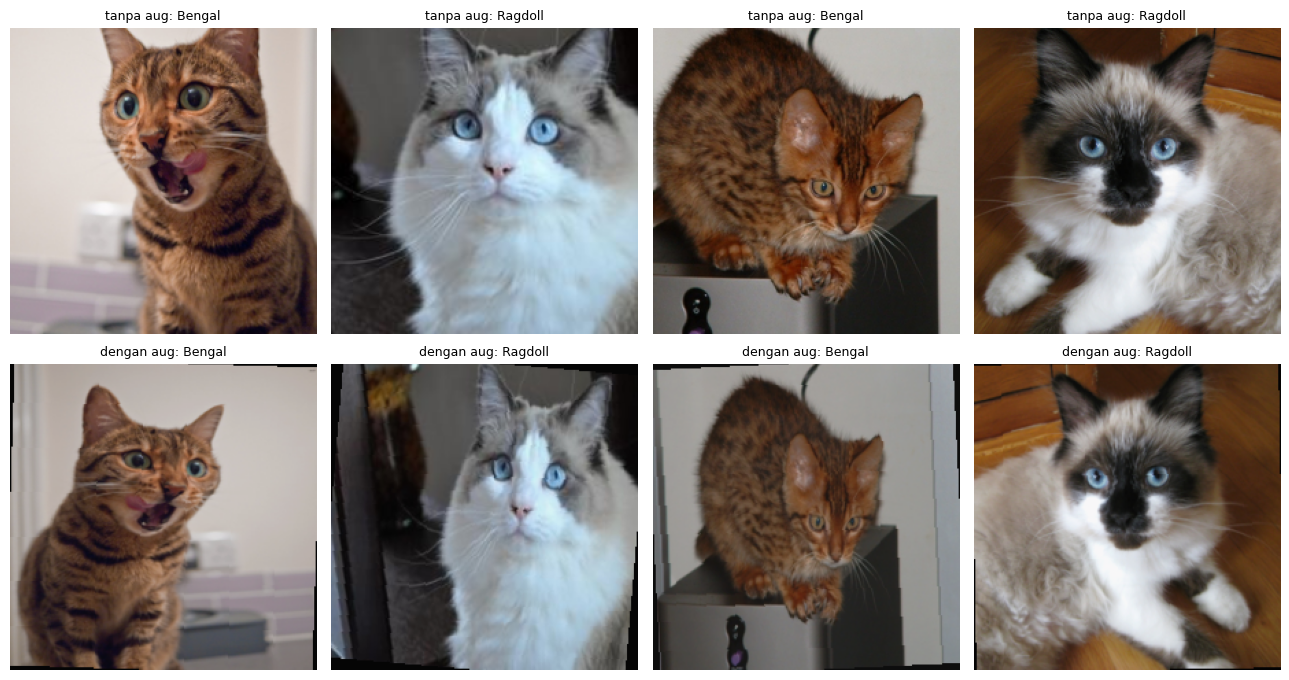

Batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


In [11]:
plain_ds = PetSubset(paths, labels, idx_train, tf_plain)
aug_ds = PetSubset(paths, labels, idx_train, tf_aug)
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for col in range(4):
    for row, ds in enumerate([plain_ds, aug_ds]):
        img, y = ds[col]
        img = (img * std_t + mean_t).clamp(0, 1)
        axes[row, col].imshow(img.permute(1, 2, 0).numpy())
        axes[row, col].set_title(f"{'tanpa aug' if row == 0 else 'dengan aug'}: {new_class_names[y]}", fontsize=9)
        axes[row, col].axis('off')
plt.tight_layout()
plt.savefig(f'{BASE}/figures/sample_augmented.png', dpi=150)
plt.show()

xb, yb = next(iter(make_loader(make_datasets(True)[0], True)))
print('Batch:', xb.shape, yb.shape)

## 4. Mesin training

### 4.1 RunLogger
Mencatat dua jenis log per run:
- `<run_id>_epochs.csv`: satu baris per epoch (loss, accuracy, learning rate tiap kelompok parameter, durasi epoch). **Ditulis ulang setiap epoch**, jadi aman jika Colab putus.
- `<run_id>_summary.json`: ringkasan akhir run (parameter, epoch konvergen, durasi, akurasi, Macro F1, konfigurasi).

Seluruh angka laporan bersumber dari file-file ini (catatan penilaian data empiris pada soal).

In [12]:
class RunLogger:
    """Mencatat log per-epoch (CSV) dan ringkasan run (JSON)."""

    def __init__(self, run_id, log_dir):
        self.run_id = run_id
        self.csv_path = f'{log_dir}/{run_id}_epochs.csv'
        self.json_path = f'{log_dir}/{run_id}_summary.json'
        self.rows = []

    def log_epoch(self, **kwargs):
        self.rows.append(kwargs)
        pd.DataFrame(self.rows).to_csv(self.csv_path, index=False)

    def save_summary(self, summary):
        with open(self.json_path, 'w') as f:
            json.dump(summary, f, indent=2)

### 4.2 Pembangun model per kondisi
Satu fungsi `build_model(condition, arch)` yang **selalu membuat model baru**, sehingga kondisi tidak saling mewarisi bobot (jebakan pada starter code yang kumulatif).

| Kondisi | Bobot awal | Yang dilatih | Learning rate |
|---|---|---|---|
| B1 | acak (`weights=None`) | semua parameter | 1e-3 |
| B2 | ImageNet | hanya head baru (`fc`) | 1e-3 |
| B3 | ImageNet | `layer4` + head | 1e-4 (`layer4`), 1e-3 (head) |

Untuk EfficientNet-B0 (B5) tidak ada `layer4`. Pada B3 yang dibuka adalah dua modul terakhir `features[7:]` (stage MBConv terakhir dan conv 1x1 akhir) beserta head `classifier[1]`. Ini keputusan desain yang harus disebut di laporan.

**Fungsi `frozen`:** `requires_grad=False` hanya menghentikan update bobot. Running mean/var BatchNorm tetap berubah selama `model.train()`. Karena itu modul yang dibekukan dipaksa ke `eval()` pada setiap epoch training (lihat `run_epoch`), sehingga backbone benar-benar beku.

Catatan: soal menyebut nama B3 "Progressive Fine-Tuning", tetapi deskripsinya hanya membuka `layer4` + `fc` sekaligus, bukan gradual unfreezing bertahap. Implementasi mengikuti deskripsi soal.

In [13]:
def build_model(condition, arch='resnet18', num_classes=10):
    """Mengembalikan (model, param_groups, frozen_modules)."""
    if arch == 'resnet18':
        model = models.resnet18(weights=None if condition == 'B1'
                                else models.ResNet18_Weights.IMAGENET1K_V1)
        if condition != 'B1':
            for p in model.parameters():
                p.requires_grad = False               # bekukan seluruh backbone
        model.fc = nn.Linear(model.fc.in_features, num_classes)   # head baru, selalu trainable
        head, last_block = model.fc, model.layer4
        earlier = [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]
        names = ('layer4', 'fc')
    elif arch == 'efficientnet_b0':
        assert condition != 'B1', 'B1 (from scratch) hanya untuk ResNet-18'
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head, last_block = model.classifier[1], model.features[7:]
        earlier = [model.features[:7]]
        names = ('features_7_8', 'classifier')
    else:
        raise ValueError(arch)

    if condition == 'B1':
        groups = [{'name': 'all', 'params': list(model.parameters()), 'lr': 1e-3}]
        frozen = []
    elif condition == 'B2':
        groups = [{'name': names[1], 'params': list(head.parameters()), 'lr': 1e-3}]
        frozen = earlier + [last_block]
    elif condition == 'B3':
        for p in last_block.parameters():
            p.requires_grad = True
        groups = [{'name': names[0], 'params': list(last_block.parameters()), 'lr': 1e-4},
                  {'name': names[1], 'params': list(head.parameters()), 'lr': 1e-3}]
        frozen = earlier
    else:
        raise ValueError(condition)
    return model, groups, frozen


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

### 4.3 Satu epoch dan prediksi
- `run_epoch`: satu epoch training atau evaluasi. Loss dirata-ratakan per sampel (bukan per batch) karena batch terakhir lebih kecil. Pada mode training, modul `frozen` dipaksa `eval()`.
- `predict`: mengembalikan label asli dan probabilitas softmax (bahan *confidence score* untuk C3).

In [14]:
def run_epoch(model, loader, criterion, optimizer=None, frozen=()):
    train = optimizer is not None
    if train:
        model.train()
        for m in frozen:
            m.eval()                     # BatchNorm pada bagian beku tidak ikut berubah
    else:
        model.eval()

    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        out = model(x.to(device))
        ps.append(torch.softmax(out, 1).cpu())
        ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

### 4.4 Fungsi utama satu eksperimen
Urutan kerja `train_experiment`:
1. Kunci seed, **lalu** buat model (inisialisasi head bergantung pada seed).
2. Training dengan optimizer AdamW (weight decay 1e-2) dan CrossEntropyLoss.
3. **Early stopping** memantau validation loss; bobot terbaik disimpan dan dipulihkan di akhir.
4. Hitung `train_acc_eval_mode`: akurasi train yang dihitung ulang dengan model final dalam mode eval **tanpa augmentasi**, supaya gap train-val adil (akurasi train saat training dihitung sambil bobot berubah dan, pada kondisi aug, dengan gambar terdistorsi).
5. **Test set dipakai sekali** di akhir untuk Akurasi dan Macro F1, tidak pernah untuk memilih epoch atau hyperparameter.
6. Simpan log CSV, ringkasan JSON, prediksi test (`.npz`), dan checkpoint terbaik (`.pt`).

**Definisi yang harus dicantumkan di laporan:**
- *Epoch konvergen* (`best_epoch`) = epoch dengan validation loss terendah.
- `best_val_acc` = akurasi validasi **pada epoch tersebut**, bukan akurasi validasi tertinggi sepanjang training.
- Durasi pelatihan = dari epoch pertama sampai berhenti (termasuk epoch patience).
- `max_epochs=40`, `patience=5` (batas atas yang diizinkan protokol), dan LR B1/B2 = 1e-3 adalah pilihan sendiri karena soal tidak menentukan.

In [15]:
def train_experiment(condition, use_aug, seed=42, arch='resnet18', max_epochs=40, patience=5,
                     tag='', resume=False):
    run_id = f"{condition}_{'aug' if use_aug else 'noaug'}_s{seed}{tag}"
    if arch != 'resnet18':
        run_id += f'_{arch}'
    json_path = f'{BASE}/logs/{run_id}_summary.json'
    if resume and os.path.exists(json_path):
        print(f'[{run_id}] sudah ada, dilewati (RESUME=True)')
        return json.load(open(json_path))

    set_seed(seed)                                    # seed dulu, baru model dibuat
    train_ds, val_ds, test_ds = make_datasets(use_aug)
    train_loader = make_loader(train_ds, True, seed)
    val_loader = make_loader(val_ds, False, seed)
    test_loader = make_loader(test_ds, False, seed)

    model, groups, frozen = build_model(condition, arch)
    model = model.to(device)
    trainable, total = count_params(model)
    print(f'[{run_id}] trainable {trainable:,} / {total:,}')

    optimizer = torch.optim.AdamW(groups, weight_decay=1e-2)
    criterion = nn.CrossEntropyLoss()
    logger = RunLogger(run_id, f'{BASE}/logs')

    best_val_loss, best_val_acc, best_epoch, best_state, wait = float('inf'), 0.0, 0, None, 0
    t0 = time.perf_counter()
    for epoch in range(1, max_epochs + 1):
        te = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, frozen)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        row = dict(epoch=epoch, train_loss=tr_loss, train_acc=tr_acc,
                   val_loss=va_loss, val_acc=va_acc,
                   epoch_time_s=round(time.perf_counter() - te, 2))
        for g in optimizer.param_groups:
            row[f"lr_{g['name']}"] = g['lr']
        logger.log_epoch(**row)
        print(f'ep{epoch:02d} tr {tr_loss:.3f}/{tr_acc:.3f} | va {va_loss:.3f}/{va_acc:.3f}')

        if va_loss < best_val_loss - 1e-4:            # early stopping pada validation loss
            best_val_loss, best_val_acc, best_epoch, wait = va_loss, va_acc, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= patience:
                break
    train_time = time.perf_counter() - t0

    model.load_state_dict(best_state)                 # pulihkan bobot terbaik

    train_eval_ds = PetSubset(paths, labels, idx_train, tf_plain)
    _, train_eval_acc = run_epoch(model, make_loader(train_eval_ds, False, seed), criterion)

    y_true, probs = predict(model, test_loader)       # test set dipakai SEKALI
    y_pred = probs.argmax(1)
    test_acc = float((y_pred == y_true).mean())
    macro_f1 = float(f1_score(y_true, y_pred, average='macro'))

    summary = dict(
        run_id=run_id, condition=condition, arch=arch, use_aug=use_aug, seed=seed, tag=tag,
        trainable_params=trainable, total_params=total,
        learning_rates={g['name']: g['lr'] for g in optimizer.param_groups},
        epochs_run=epoch, best_epoch=best_epoch, train_time_s=round(train_time, 2),
        best_val_loss=best_val_loss, best_val_acc=best_val_acc,
        train_acc_eval_mode=train_eval_acc, gap_train_val=train_eval_acc - best_val_acc,
        test_acc=test_acc, test_macro_f1=macro_f1,
        config=dict(batch_size=32, optimizer='AdamW', weight_decay=1e-2, max_epochs=max_epochs,
                    patience=patience, device=str(device), torch=torch.__version__,
                    split_seed=SEED),
    )
    logger.save_summary(summary)
    np.savez(f'{BASE}/logs/{run_id}_test_preds.npz', y_true=y_true, probs=probs)
    torch.save(best_state, f'{BASE}/checkpoints/{run_id}.pt')
    print(f'[{run_id}] best_ep {best_epoch} | val_acc {best_val_acc:.4f} | '
          f'test_acc {test_acc:.4f} | F1 {macro_f1:.4f} | {train_time:.0f}s')
    return summary

### 4.5 Verifikasi sebelum training sungguhan
**(a) Jumlah parameter.** Nilai yang harus muncul untuk ResNet-18 (10 kelas):
- B1: 11.181.642 trainable dari 11.181.642
- B2: 5.130 trainable (hanya `fc`)
- B3: 8.398.858 trainable (`layer4` 8.393.728 + `fc` 5.130)

Kalau berbeda, ada kesalahan pembekuan dan sel ini akan berhenti dengan error.

**(b) BatchNorm benar-benar beku.** Satu langkah training pada B2 dijalankan dua kali: dengan daftar `frozen` (statistik BatchNorm `layer4` harus tidak berubah) dan tanpanya (harus berubah). Temuan ini berguna untuk Bagian A nomor 1 dan 5.

In [16]:
EXPECTED = {'B1': (11181642, 11181642), 'B2': (5130, 11181642), 'B3': (8398858, 11181642)}
for c, exp in EXPECTED.items():
    m, _, _ = build_model(c)
    got = count_params(m)
    print(c, got)
    assert got == exp, f'Jumlah parameter {c} tidak sesuai: {got} != {exp}'
for c in ['B2', 'B3']:
    m, _, _ = build_model(c, 'efficientnet_b0')
    print('EfficientNet-B0', c, count_params(m))

# Cek BatchNorm beku
xb, yb = next(iter(make_loader(make_datasets(False)[0], True)))
batch = [(xb, yb)]
for use_frozen in [True, False]:
    set_seed(42)
    m, groups, frozen = build_model('B2')
    m = m.to(device)
    before = m.layer4[0].bn1.running_mean.clone()
    opt = torch.optim.AdamW(groups, weight_decay=1e-2)
    run_epoch(m, batch, nn.CrossEntropyLoss(), opt, frozen if use_frozen else ())
    unchanged = torch.equal(before, m.layer4[0].bn1.running_mean)
    print('pakai frozen:', use_frozen, '| statistik BN tidak berubah:', unchanged)
    assert unchanged == use_frozen

B1 (11181642, 11181642)
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 125MB/s]


B2 (5130, 11181642)
B3 (8398858, 11181642)
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 151MB/s]


EfficientNet-B0 B2 (12810, 4020358)
EfficientNet-B0 B3 (1142202, 4020358)
pakai frozen: True | statistik BN tidak berubah: True
pakai frozen: False | statistik BN tidak berubah: False


## 5. Menjalankan eksperimen

**Matriks per seed** (seed 42, 43, 44):

| Run | Kondisi | Augmentasi |
|---|---|---|
| `B1_noaug` | from scratch | tidak |
| `B2_noaug` | feature extraction | tidak |
| `B3_noaug` | fine-tuning `layer4` + `fc` | tidak |
| `B3_aug` | **B4**: B3 dengan augmentasi | ya |

Keputusan desain (tulis di laporan):
- B1-B3 **tanpa augmentasi**, sehingga "B4 tanpa augmentasi" adalah B3 yang sama dan hanya satu run tambahan yang dibutuhkan.
- B4 dijalankan pada B3 karena B3 mengalami overfit paling jelas (train acc mendekati 100%).
- Seed 42/43/44 hanya mengubah inisialisasi dan urutan shuffle. **Split data tetap memakai seed 42.**
- Early stopping memakai patience 5 untuk semua kondisi (patuh protokol 4.2).

**Run tambahan di luar protokol:** `B1_noaug_long` (patience 15, maksimum 60 epoch) untuk memeriksa apakah baseline B1 berhenti terlalu cepat. Run ini ditampilkan terpisah dan **tidak dicampur** dengan B1 protokol.

Sakelar:
- `RESUME = True` melewati run yang sudah punya `summary.json` (berguna jika Colab terputus).
- `RUN_B2_AUG = True` menambahkan B2 dengan augmentasi (opsional, ±4 menit per seed).

Satu sel per seed supaya jika runtime putus, hanya satu bagian yang perlu diulang.

In [17]:
RESUME = True
RUN_B2_AUG = False


def run_main_matrix(seed):
    train_experiment('B1', False, seed, resume=RESUME)
    train_experiment('B2', False, seed, resume=RESUME)
    train_experiment('B3', False, seed, resume=RESUME)
    train_experiment('B3', True, seed, resume=RESUME)           # B4
    if RUN_B2_AUG:
        train_experiment('B2', True, seed, resume=RESUME)

In [18]:
run_main_matrix(42)

[B1_noaug_s42] sudah ada, dilewati (RESUME=True)
[B2_noaug_s42] sudah ada, dilewati (RESUME=True)
[B3_noaug_s42] sudah ada, dilewati (RESUME=True)
[B3_aug_s42] sudah ada, dilewati (RESUME=True)


In [19]:
# Di luar protokol: baseline B1 dengan patience lebih panjang
_ = train_experiment('B1', False, 42, max_epochs=60, patience=15, tag='_long', resume=RESUME)

[B1_noaug_s42_long] sudah ada, dilewati (RESUME=True)


In [20]:
run_main_matrix(43)

[B1_noaug_s43] sudah ada, dilewati (RESUME=True)
[B2_noaug_s43] sudah ada, dilewati (RESUME=True)
[B3_noaug_s43] sudah ada, dilewati (RESUME=True)
[B3_aug_s43] sudah ada, dilewati (RESUME=True)


In [21]:
run_main_matrix(44)

[B1_noaug_s44] sudah ada, dilewati (RESUME=True)
[B2_noaug_s44] sudah ada, dilewati (RESUME=True)
[B3_noaug_s44] sudah ada, dilewati (RESUME=True)
[B3_aug_s44] sudah ada, dilewati (RESUME=True)


## 6. Konsolidasi hasil (C1)

Semua tabel di bawah **dibaca dari file log**, bukan diketik manual:
- `summary_all.csv`: satu baris per run.
- `summary_agg.csv`: rata-rata ± standar deviasi (n=3 seed) per kondisi, untuk tabel C1.
- Kolom `sec_per_epoch` adalah rata-rata durasi per epoch. Gunakan kolom ini (bukan `train_time_s`) untuk membandingkan beban komputasi antar kondisi, karena `train_time_s` bergantung pada seberapa cepat early stopping terjadi.
- `gap` = `train_acc` (mode eval, tanpa augmentasi) dikurangi `val_acc`.
- Standar deviasi memakai `ddof=1` (sample std). Dengan n=3 seed, angka ini hanya indikasi kasar.

In [22]:
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', None)

METRICS = [('best_epoch', 1), ('train_time_s', 0), ('sec_per_epoch', 1), ('train_acc', 4),
           ('val_acc', 4), ('gap', 4), ('test_acc', 4), ('test_f1', 4)]


def load_runs():
    rows = []
    for f in sorted(glob.glob(f'{BASE}/logs/*_summary.json')):
        s = json.load(open(f))
        ep = pd.read_csv(f.replace('_summary.json', '_epochs.csv'))
        rows.append(dict(
            run_id=s['run_id'], group=re.sub(r'_s\d+', '', s['run_id']), seed=s['seed'],
            arch=s.get('arch', 'resnet18'), trainable=s['trainable_params'], total=s['total_params'],
            lr=json.dumps(s['learning_rates']), epochs_run=s['epochs_run'], best_epoch=s['best_epoch'],
            train_time_s=s['train_time_s'], sec_per_epoch=ep['epoch_time_s'].mean(),
            train_acc=s['train_acc_eval_mode'], val_acc=s['best_val_acc'], val_loss=s['best_val_loss'],
            gap=s['gap_train_val'], test_acc=s['test_acc'], test_f1=s['test_macro_f1']))
    return pd.DataFrame(rows)


def fmt_ms(x, nd):
    x = pd.Series(x)
    if len(x) > 1:
        return f'{x.mean():.{nd}f} ± {x.std(ddof=1):.{nd}f}'
    return f'{x.iloc[0]:.{nd}f} (n=1)'


def build_tables():
    df = load_runs()
    agg_rows, num_rows = [], []
    for g, d in df.groupby('group'):
        r = {'group': g, 'n_seed': len(d), 'trainable': int(d.trainable.iloc[0]),
             'total': int(d.total.iloc[0]), 'lr': d.lr.iloc[0]}
        n = {'group': g, 'n_seed': len(d)}
        for col, nd in METRICS:
            r[col] = fmt_ms(d[col], nd)
            n[col + '_mean'] = d[col].mean()
            n[col + '_std'] = d[col].std(ddof=1) if len(d) > 1 else float('nan')
        agg_rows.append(r)
        num_rows.append(n)
    return df, pd.DataFrame(agg_rows), pd.DataFrame(num_rows)


df, agg, agg_num = build_tables()
df.to_csv(f'{BASE}/logs/summary_all.csv', index=False)
agg.to_csv(f'{BASE}/logs/summary_agg.csv', index=False)
agg_num.to_csv(f'{BASE}/logs/summary_agg_numeric.csv', index=False)

print('=== Per run ===')
display(df.drop(columns=['lr']).round(4))
print('=== Rata-rata ± std per kondisi (tabel C1) ===')
display(agg)

=== Per run ===


,run_id,group,seed,arch,trainable,total,epochs_run,best_epoch,train_time_s,sec_per_epoch,train_acc,val_acc,val_loss,gap,test_acc,test_f1
0,B1_noaug_s42_long,B1_noaug_long,42,resnet18,11181642,11181642,34,19,392.22,11.5082,0.9429,0.4696,1.7717,0.4733,0.5185,0.5137
1,B1_noaug_s42,B1_noaug,42,resnet18,11181642,11181642,9,4,103.86,11.4444,0.4064,0.3446,1.8632,0.0618,0.3569,0.3215
2,B1_noaug_s43,B1_noaug,43,resnet18,11181642,11181642,13,8,154.23,11.8169,0.5466,0.4493,1.6910,0.0973,0.4545,0.4369
3,B1_noaug_s44,B1_noaug,44,resnet18,11181642,11181642,10,5,116.49,11.5790,0.4526,0.3818,1.7269,0.0709,0.3737,0.3407
4,B2_noaug_s42,B2_noaug,42,resnet18,5130,11181642,19,14,199.24,10.4442,0.9754,0.8818,0.3051,0.0937,0.8788,0.8744
5,B2_noaug_s43,B2_noaug,43,resnet18,5130,11181642,24,19,253.29,10.5163,0.9826,0.8851,0.3002,0.0975,0.8822,0.8787
6,B2_noaug_s44,B2_noaug,44,resnet18,5130,11181642,20,15,211.79,10.5465,0.9783,0.8919,0.2836,0.0864,0.8754,0.8732
7,B3_aug_s42,B3_aug,42,resnet18,8398858,11181642,7,2,104.63,14.9371,0.9559,0.9054,0.2832,0.0505,0.8586,0.8569
8,B3_aug_s43,B3_aug,43,resnet18,8398858,11181642,7,2,106.00,15.0143,0.9371,0.8986,0.3051,0.0384,0.8923,0.8901
9,B3_aug_s44,B3_aug,44,resnet18,8398858,11181642,11,6,165.46,14.9782,0.9899,0.8986,0.2643,0.0912,0.8721,0.8708


=== Rata-rata ± std per kondisi (tabel C1) ===


,group,n_seed,trainable,total,lr,best_epoch,train_time_s,sec_per_epoch,train_acc,val_acc,gap,test_acc,test_f1
0,B1_noaug,3,11181642,11181642,"{""all"": 0.001}",5.7 ± 2.1,125 ± 26,11.6 ± 0.2,0.4685 ± 0.0715,0.3919 ± 0.0531,0.0767 ± 0.0185,0.3951 ± 0.0522,0.3663 ± 0.0618
1,B1_noaug_long,1,11181642,11181642,"{""all"": 0.001}",19.0 (n=1),392 (n=1),11.5 (n=1),0.9429 (n=1),0.4696 (n=1),0.4733 (n=1),0.5185 (n=1),0.5137 (n=1)
2,B2_noaug,3,5130,11181642,"{""fc"": 0.001}",16.0 ± 2.6,221 ± 28,10.5 ± 0.1,0.9788 ± 0.0036,0.8863 ± 0.0052,0.0925 ± 0.0056,0.8788 ± 0.0034,0.8754 ± 0.0029
3,B3_aug,3,8398858,11181642,"{""layer4"": 0.0001, ""fc"": 0.001}",3.3 ± 2.3,125 ± 35,15.0 ± 0.0,0.9610 ± 0.0268,0.9009 ± 0.0039,0.0601 ± 0.0277,0.8743 ± 0.0169,0.8726 ± 0.0167
4,B3_noaug,3,8398858,11181642,"{""layer4"": 0.0001, ""fc"": 0.001}",2.3 ± 0.6,79 ± 6,10.6 ± 0.0,0.9986 ± 0.0014,0.9077 ± 0.0078,0.0909 ± 0.0091,0.9035 ± 0.0097,0.9015 ± 0.0097


### Kurva training loss vs validation loss (C1)
Garis putus-putus abu-abu menandai `best_epoch` (epoch dengan validation loss terendah). Yang ditampilkan adalah seed 42.

Catatan membaca kurva: loss train dicatat saat model dalam mode `train()` dengan bobot yang berubah sepanjang epoch, sehingga tidak persis sebanding dengan val loss yang dihitung dalam mode `eval()`.

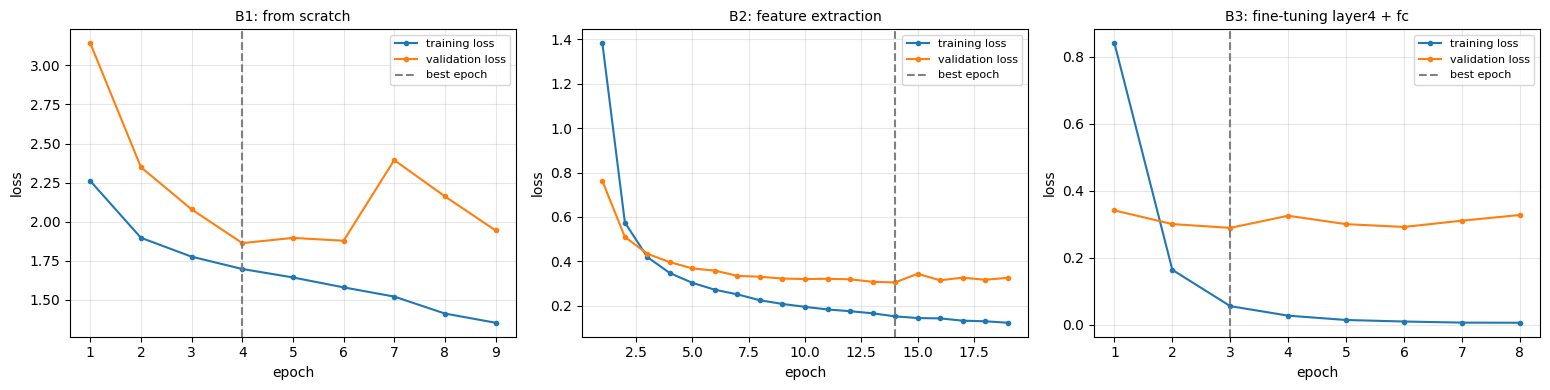

In [23]:
def plot_curves(run_ids, titles, fname):
    fig, axes = plt.subplots(1, len(run_ids), figsize=(5.2 * len(run_ids), 4))
    axes = np.atleast_1d(axes)
    for ax, rid, title in zip(axes, run_ids, titles):
        ep = pd.read_csv(f'{BASE}/logs/{rid}_epochs.csv')
        s = json.load(open(f'{BASE}/logs/{rid}_summary.json'))
        ax.plot(ep.epoch, ep.train_loss, marker='o', ms=3, label='training loss')
        ax.plot(ep.epoch, ep.val_loss, marker='o', ms=3, label='validation loss')
        ax.axvline(s['best_epoch'], ls='--', c='gray', label='best epoch')
        ax.set_title(title, fontsize=10)
        ax.set_xlabel('epoch')
        ax.set_ylabel('loss')
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{BASE}/figures/{fname}', dpi=150)
    plt.show()


plot_curves(['B1_noaug_s42', 'B2_noaug_s42', 'B3_noaug_s42'],
            ['B1: from scratch', 'B2: feature extraction', 'B3: fine-tuning layer4 + fc'],
            'curves_B1_B2_B3.png')

### Analisis : C2 pertanyaan 1 dan 2
Kaitkan dengan konsep Slide 10-12, 16, 20, dan 28, dan gunakan **angka dari tabel di atas** (mean ± std, bukan satu run saja):
1. Mengapa B1 jauh di bawah B2 dan B3?
2. Bagaimana trade-off performa vs stabilitas antara feature extraction (B2) dan fine-tuning (B3) pada data terbatas ini? Perhatikan juga apakah selisihnya lebih besar daripada std antar seed.

*(Hasil analisis terdapat pada laporan)*

## 7. Analisis B4: efek augmentasi

Perbandingan `B3_noaug` dan `B3_aug` (dan `B2` jika `RUN_B2_AUG=True`). Kolom penting:
- `gap`: selisih akurasi train (mode eval, tanpa augmentasi) dan akurasi validasi.
- `val_acc` dan `test_f1`: apakah augmentasi benar-benar meningkatkan generalisasi?
- `best_epoch`: augmentasi biasanya memperlambat konvergensi.

Tabel per seed ditampilkan juga agar kamu bisa melihat konsistensi arah efeknya.

,group,n_seed,best_epoch,train_acc,val_acc,gap,test_acc,test_f1
2,B2_noaug,3,16.0 ± 2.6,0.9788 ± 0.0036,0.8863 ± 0.0052,0.0925 ± 0.0056,0.8788 ± 0.0034,0.8754 ± 0.0029
3,B3_aug,3,3.3 ± 2.3,0.9610 ± 0.0268,0.9009 ± 0.0039,0.0601 ± 0.0277,0.8743 ± 0.0169,0.8726 ± 0.0167
4,B3_noaug,3,2.3 ± 0.6,0.9986 ± 0.0014,0.9077 ± 0.0078,0.0909 ± 0.0091,0.9035 ± 0.0097,0.9015 ± 0.0097


gap                   test_f1                   val_acc                 
group B2_noaug  B3_aug B3_noaug B2_noaug  B3_aug B3_noaug B2_noaug  B3_aug B3_noaug
seed                                                                               
42      0.0937  0.0505   0.1014   0.8744  0.8569   0.9077   0.8818  0.9054   0.8986
43      0.0975  0.0384   0.0849   0.8787  0.8901   0.9064   0.8851  0.8986   0.9122
44      0.0864  0.0912   0.0864   0.8732  0.8708   0.8904   0.8919  0.8986   0.9122

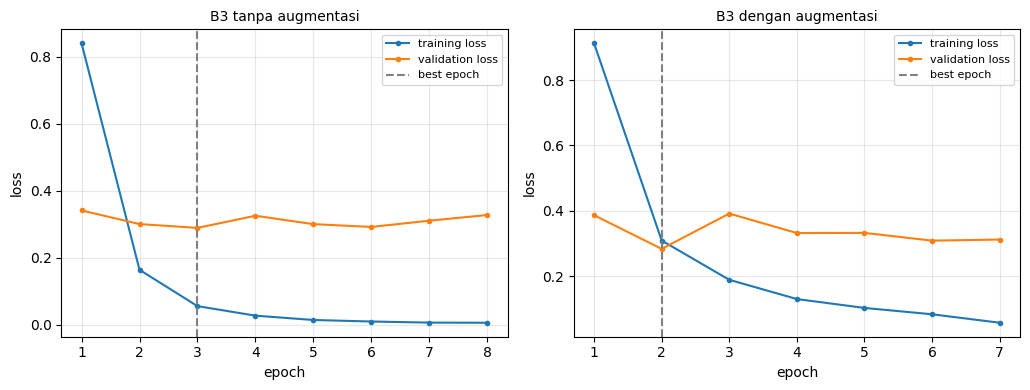

In [24]:
b4_groups = agg[agg.group.str.match(r'^B[23]_(noaug|aug)$')]
display(b4_groups[['group', 'n_seed', 'best_epoch', 'train_acc', 'val_acc', 'gap', 'test_acc', 'test_f1']])

per_seed = df[df.group.str.match(r'^B[23]_(noaug|aug)$')]
display(per_seed.pivot_table(index='seed', columns='group', values=['val_acc', 'gap', 'test_f1']).round(4))

plot_curves(['B3_noaug_s42', 'B3_aug_s42'],
            ['B3 tanpa augmentasi', 'B3 dengan augmentasi'],
            'curves_B4_B3_aug.png')

### Analisis : C2 pertanyaan 3
Sejauh mana augmentasi meredam overfitting? Gunakan celah `gap`, bentuk kurva loss, dan `val_acc` / `test_f1`. Cantumkan seberapa konsisten efeknya di tiga seed, dan sebutkan jika selisihnya masih berada dalam rentang noise.

*(Hasil analisis terdapat pada laporan)*

## 8. B5: arsitektur pembanding (bonus)

Konfigurasi terbaik ResNet-18 dipilih **berdasarkan rata-rata `val_acc`** (bukan test) di antara B2/B3 dengan atau tanpa augmentasi, supaya test set tidak ikut menentukan pilihan. Konfigurasi itu dijalankan pada EfficientNet-B0 dengan protokol yang sama (3 seed, batch 32, AdamW, patience 5).

Hal yang harus dibahas di laporan: Macro F1, jumlah parameter, dan durasi komputasi (Slide 24). Catatan : transform input EfficientNet-B0 disamakan dengan ResNet-18 (Resize 256, CenterCrop 224) demi perbandingan yang adil, sehingga tidak persis memakai preprocessing bawaan EfficientNet.

In [25]:
cand = agg_num[agg_num.group.str.match(r'^B[23]_(noaug|aug)$')]
best_cfg = cand.sort_values('val_acc_mean', ascending=False).iloc[0]
best_group = best_cfg.group
b5_cond = best_group[:2]
b5_aug = best_group.endswith('_aug')
print('Konfigurasi terbaik ResNet-18 (val_acc):', best_group, round(best_cfg.val_acc_mean, 4))
print('Dijalankan pada EfficientNet-B0:', b5_cond, '| augmentasi:', b5_aug)

Konfigurasi terbaik ResNet-18 (val_acc): B3_noaug 0.9077
Dijalankan pada EfficientNet-B0: B3 | augmentasi: False


In [26]:
for seed in SEEDS:
    train_experiment(b5_cond, b5_aug, seed, arch='efficientnet_b0', resume=RESUME)

[B3_noaug_s42_efficientnet_b0] trainable 1,142,202 / 4,020,358
ep01 tr 1.075/0.753 | va 0.386/0.899
ep02 tr 0.313/0.905 | va 0.266/0.902
ep03 tr 0.211/0.936 | va 0.245/0.909
ep04 tr 0.149/0.960 | va 0.215/0.919
ep05 tr 0.115/0.972 | va 0.224/0.916
ep06 tr 0.094/0.975 | va 0.203/0.929
ep07 tr 0.065/0.986 | va 0.211/0.916
ep08 tr 0.052/0.991 | va 0.224/0.922
ep09 tr 0.042/0.993 | va 0.198/0.922
ep10 tr 0.036/0.993 | va 0.227/0.926
ep11 tr 0.029/0.997 | va 0.229/0.926
ep12 tr 0.024/0.995 | va 0.226/0.922
ep13 tr 0.016/0.999 | va 0.223/0.929
ep14 tr 0.015/0.999 | va 0.210/0.926
[B3_noaug_s42_efficientnet_b0] best_ep 9 | val_acc 0.9223 | test_acc 0.9327 | F1 0.9311 | 140s
[B3_noaug_s43_efficientnet_b0] trainable 1,142,202 / 4,020,358
ep01 tr 1.058/0.756 | va 0.406/0.875
ep02 tr 0.316/0.911 | va 0.274/0.899
ep03 tr 0.204/0.939 | va 0.250/0.909
ep04 tr 0.157/0.956 | va 0.229/0.912
ep05 tr 0.116/0.968 | va 0.228/0.916
ep06 tr 0.092/0.978 | va 0.238/0.909
ep07 tr 0.071/0.982 | va 0.222/0.919
ep

In [27]:
df, agg, agg_num = build_tables()
df.to_csv(f'{BASE}/logs/summary_all.csv', index=False)
agg.to_csv(f'{BASE}/logs/summary_agg.csv', index=False)
agg_num.to_csv(f'{BASE}/logs/summary_agg_numeric.csv', index=False)

cmp_groups = [best_group, best_group + '_efficientnet_b0']
display(agg[agg.group.isin(cmp_groups)][
    ['group', 'n_seed', 'trainable', 'total', 'test_f1', 'train_time_s', 'sec_per_epoch', 'best_epoch']])

,group,n_seed,trainable,total,test_f1,train_time_s,sec_per_epoch,best_epoch
4,B3_noaug,3,8398858,11181642,0.9015 ± 0.0097,79 ± 6,10.6 ± 0.0,2.3 ± 0.6
5,B3_noaug_efficientnet_b0,3,1142202,4020358,0.9279 ± 0.0090,132 ± 13,9.9 ± 0.1,8.3 ± 1.2


### Analisis : trade-off B5
Bandingkan ResNet-18 vs EfficientNet-B0: Macro F1, jumlah parameter total dan trainable, durasi per epoch.

*(Hasil analisis terdapat pada laporan)*

## 9. Failure analysis (C3)

**Pemilihan model:** run dengan `val_acc` tertinggi (tie-break: `val_loss` terendah) di antara semua run. Dipilih berdasarkan validation, bukan test. Perlu dicatat bahwa memilih satu seed terbaik dari tiga seed adalah seleksi yang sedikit optimistis; sebutkan di laporan.

**Pemilihan sampel:** 8 kesalahan pada test set dengan **confidence salah tertinggi** (kesalahan paling "yakin", paling informatif untuk dianalisis). Tulis kriteria pemilihan ini di laporan.

Yang ditampilkan: gambar input, label aktual (GT), prediksi beserta confidence, plus confusion matrix dan laporan per kelas. Bagian hipotesis penyebab wajib kamu tulis sendiri setelah melihat gambarnya (ambiguitas antar ras, sudut ekstrem, oklusi, pencahayaan, bias latar belakang, dst.).

Model terbaik (berdasarkan validation): B3_noaug_s44_efficientnet_b0 | val_acc 0.9358 | test_f1 0.9349
Salah: 19 dari 297 (akurasi 0.9360)


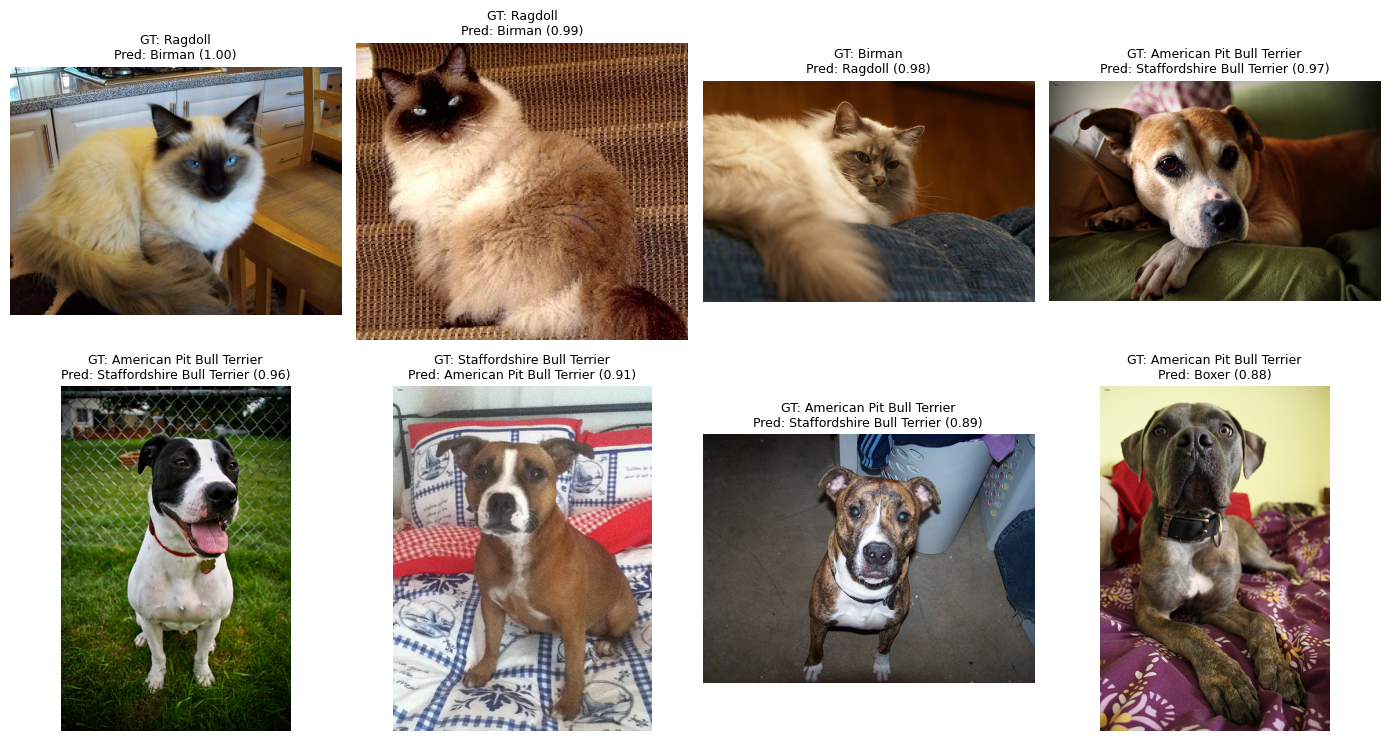

,test_idx,file,ground_truth,prediction,confidence,prob_true_class
0,266,Ragdoll_35.jpg,Ragdoll,Birman,0.996,0.004
1,9,Ragdoll_208.jpg,Ragdoll,Birman,0.989,0.010
2,130,Birman_79.jpg,Birman,Ragdoll,0.978,0.021
3,196,american_pit_bull_terrier_26.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.966,0.034
4,77,american_pit_bull_terrier_98.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.963,0.029
5,155,staffordshire_bull_terrier_70.jpg,Staffordshire Bull Terrier,American Pit Bull Terrier,0.906,0.087
6,239,american_pit_bull_terrier_53.jpg,American Pit Bull Terrier,Staffordshire Bull Terrier,0.892,0.107
7,49,american_pit_bull_terrier_106.jpg,American Pit Bull Terrier,Boxer,0.880,0.081


In [28]:
best_row = df.sort_values(['val_acc', 'val_loss'], ascending=[False, True]).iloc[0]
rid = best_row.run_id
print('Model terbaik (berdasarkan validation):', rid, '| val_acc', round(best_row.val_acc, 4),
      '| test_f1', round(best_row.test_f1, 4))

d = np.load(f'{BASE}/logs/{rid}_test_preds.npz')
y_true, probs = d['y_true'], d['probs']
y_pred, conf = probs.argmax(1), probs.max(1)
wrong = np.where(y_pred != y_true)[0]
print(f'Salah: {len(wrong)} dari {len(y_true)} (akurasi {1 - len(wrong) / len(y_true):.4f})')

show = wrong[np.argsort(-conf[wrong])][:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax in axes.flat:
    ax.axis('off')
records = []
for ax, k in zip(axes.flat, show):
    j = idx_test[k]                                   # urutan test_loader (shuffle=False) = idx_test
    ax.imshow(Image.open(paths[j]).convert('RGB'))
    ax.set_title(f'GT: {new_class_names[y_true[k]]}\nPred: {new_class_names[y_pred[k]]} ({conf[k]:.2f})',
                 fontsize=9)
    records.append(dict(test_idx=int(k), file=Path(paths[j]).name,
                        ground_truth=new_class_names[y_true[k]],
                        prediction=new_class_names[y_pred[k]], confidence=float(conf[k]),
                        prob_true_class=float(probs[k, y_true[k]])))
plt.tight_layout()
plt.savefig(f'{BASE}/figures/failure_cases.png', dpi=150)
plt.show()

fail_df = pd.DataFrame(records)
fail_df.to_csv(f'{BASE}/logs/failure_cases.csv', index=False)
display(fail_df.round(3))

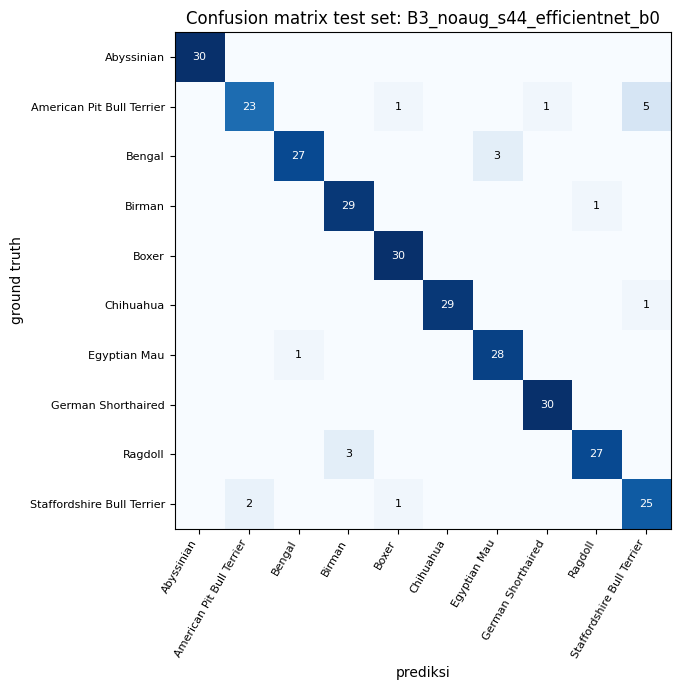

,precision,recall,f1-score,support
Abyssinian,1.000,1.000,1.000,30.000
American Pit Bull Terrier,0.920,0.767,0.836,30.000
Bengal,0.964,0.900,0.931,30.000
Birman,0.906,0.967,0.935,30.000
Boxer,0.938,1.000,0.968,30.000
Chihuahua,1.000,0.967,0.983,30.000
Egyptian Mau,0.903,0.966,0.933,29.000
German Shorthaired,0.968,1.000,0.984,30.000
Ragdoll,0.964,0.900,0.931,30.000
Staffordshire Bull Terrier,0.806,0.893,0.847,28.000


In [29]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10))
ax.set_xticklabels(new_class_names, rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(10))
ax.set_yticklabels(new_class_names, fontsize=8)
ax.set_xlabel('prediksi')
ax.set_ylabel('ground truth')
for i in range(10):
    for j2 in range(10):
        if cm[i, j2]:
            ax.text(j2, i, cm[i, j2], ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j2] > cm.max() / 2 else 'black')
ax.set_title(f'Confusion matrix test set: {rid}')
plt.tight_layout()
plt.savefig(f'{BASE}/figures/confusion_matrix.png', dpi=150)
plt.show()

rep = pd.DataFrame(classification_report(y_true, y_pred, target_names=new_class_names,
                                         output_dict=True, zero_division=0)).T
rep.to_csv(f'{BASE}/logs/classification_report.csv')
display(rep.round(3))

### Analisis : C3 hipotesis penyebab
Untuk setiap sampel kesalahan di atas tulis hipotesis teknisnya. Periksa juga pola pada confusion matrix: apakah kesalahan terbanyak ada pada pasangan ras yang sengaja dipilih mirip (Ragdoll/Birman, American Pit Bull Terrier/Staffordshire Bull Terrier), atau pola lain?

*(Hasil analisis terdapat pada laporan)*

## 10. Grad-CAM pada `layer4`: sebelum vs sesudah fine-tuning (C5, opsional)

**Idea:** bandingkan `B2_noaug_s42` (backbone beku, representasi `layer4` masih milik ImageNet) dengan `B3_noaug_s42` (`layer4` sudah disesuaikan dengan domain hewan peliharaan). Keduanya memakai seed dan split yang sama.

**Cara kerja Grad-CAM (Selvaraju et al., 2017):**
1. Ambil aktivasi `A` (512 channel x 7 x 7) dari `layer4` dan gradien skor kelas target terhadap `A`.
2. Bobot tiap channel = rata-rata gradiennya.
3. Peta = ReLU(jumlah berbobot channel), di-upsample ke 224x224 dan dinormalisasi 0-1.

Target kelas = label sebenarnya. Gambar diambil dari 4 kesalahan model terbaik di bagian 9 (bisa kamu ganti). Perhatikan bahwa gambar input harus diberi `requires_grad` agar grafik gradien terbentuk walau backbone beku.

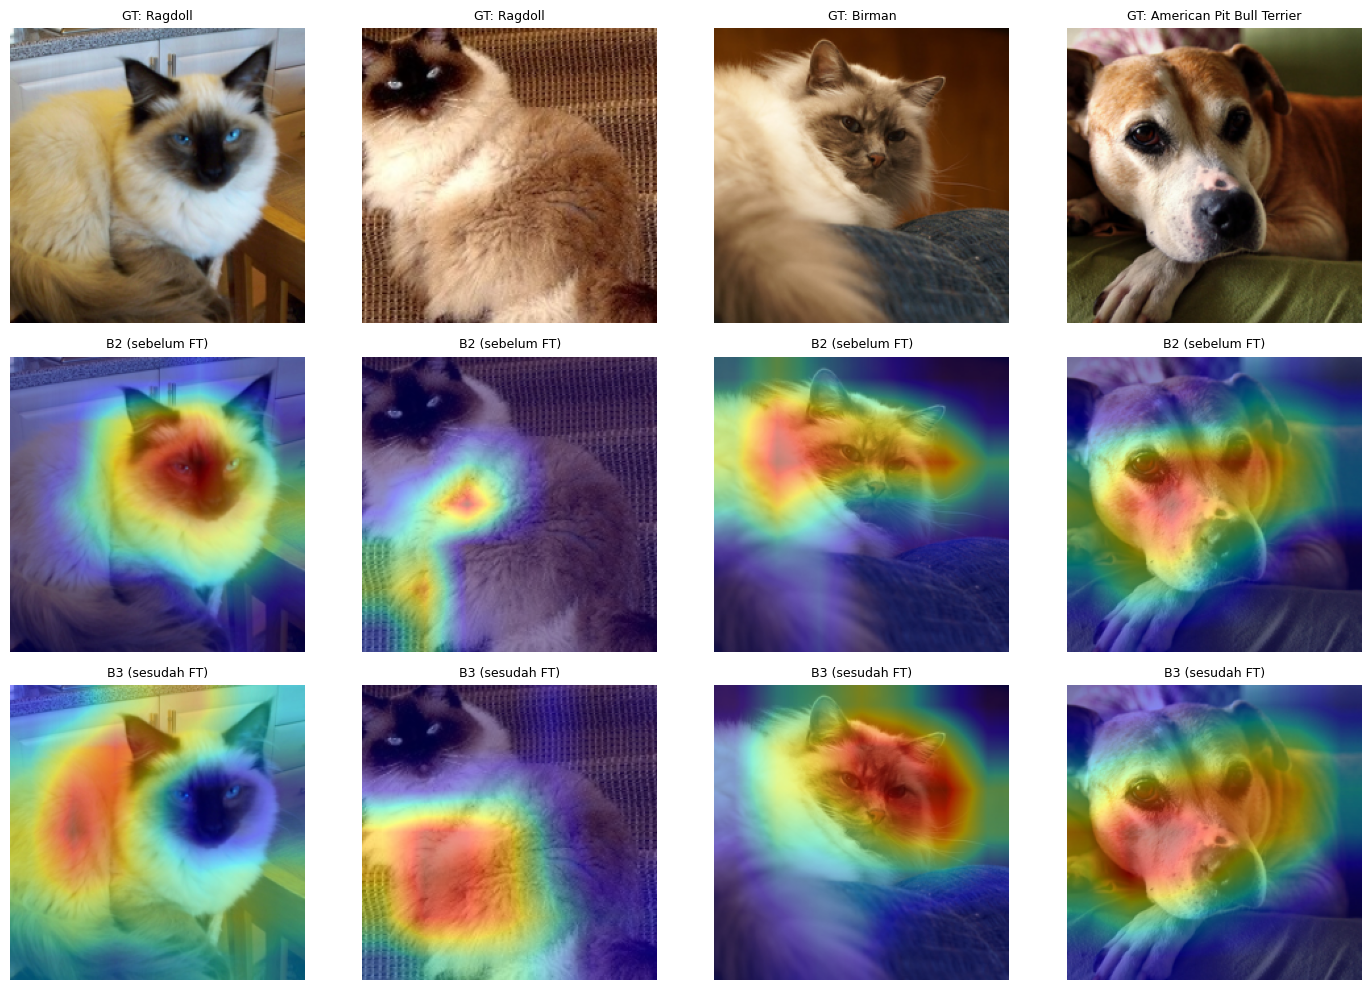

In [30]:
def load_ckpt_model(run_id, condition):
    m, _, _ = build_model(condition)
    m.load_state_dict(torch.load(f'{BASE}/checkpoints/{run_id}.pt', map_location='cpu'))
    return m.to(device).eval()


def gradcam(model, x, target):
    feats = {}

    def fwd_hook(module, inp, out):
        feats['a'] = out
        out.register_hook(lambda g: feats.__setitem__('g', g))

    h = model.layer4.register_forward_hook(fwd_hook)
    x = x.clone().requires_grad_(True)
    model.zero_grad(set_to_none=True)
    out = model(x)
    out[0, target].backward()
    h.remove()

    a, g = feats['a'].detach(), feats['g']
    w = g.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode='bilinear', align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.cpu().numpy()


model_b2 = load_ckpt_model('B2_noaug_s42', 'B2')
model_b3 = load_ckpt_model('B3_noaug_s42', 'B3')

cam_ids = list(show[:4])
fig, axes = plt.subplots(3, len(cam_ids), figsize=(3.6 * len(cam_ids), 10))
axes = np.atleast_2d(axes).reshape(3, -1)
for col, k in enumerate(cam_ids):
    j = idx_test[k]
    pil = Image.open(paths[j]).convert('RGB')
    x = tf_plain(pil).unsqueeze(0).to(device)
    img = (x[0].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    target = int(y_true[k])
    axes[0, col].imshow(img)
    axes[0, col].set_title(f'GT: {new_class_names[target]}', fontsize=9)
    for row, (name, mdl) in enumerate([('B2 (sebelum FT)', model_b2), ('B3 (sesudah FT)', model_b3)], start=1):
        cam = gradcam(mdl, x, target)
        axes[row, col].imshow(img)
        axes[row, col].imshow(cam, cmap='jet', alpha=0.45)
        axes[row, col].set_title(name, fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig(f'{BASE}/figures/gradcam_B2_vs_B3.png', dpi=150)
plt.show()

### Analisis : C5
Bagaimana area yang diperhatikan model bergeser setelah fine-tuning? Apakah sebelum fine-tuning model lebih terpengaruh latar belakang, dan apakah sesudahnya fokus pada wajah atau tubuh hewan?

*(Hasil analisis terdapat pada laporan)*

## 11. Penutup dan daftar artefak

Semua berkas berada di `MyDrive/Tugas05/`:

| Berkas / folder | Kegunaan |
|---|---|
| `logs/*_epochs.csv`, `logs/*_summary.json` | Log mentah per run (bukti untuk semua angka di laporan) |
| `logs/summary_all.csv`, `summary_agg.csv` | Tabel konsolidasi C1 |
| `logs/split_seed42.json`, `class_distribution.csv` | Bukti split dan pemilihan kelas |
| `logs/failure_cases.csv`, `classification_report.csv` | Bahan C3 |
| `logs/env.json`, `requirements.txt` | Reproduksibilitas |
| `figures/*.png` | Gambar untuk laporan |
| `checkpoints/*.pt` | Bobot terbaik tiap run (jangan dikumpulkan jika ukurannya besar) |

**Checklist akhir:**
- [ ] Notebook dijalankan **Run all** dari awal tanpa error, seluruh output tersimpan.
- [ ] Angka di laporan dicocokkan ulang dengan `summary_agg.csv` (eksekusi final).
- [ ] Sel "Analisis (tulis sendiri)" sudah diisi di laporan (C2, C3, C4, C5).
- [ ] Batasan studi disebut di C4: split dan subset kelas dirancang sengaja, 3 seed saja, split tetap seed 42, 10 kelas, dataset kecil sehingga selisih kecil bisa berada dalam noise, durasi epoch kemungkinan dibatasi I/O disk.
- [ ] Penyimpangan dari protokol dicantumkan: B1 `_long` (patience 15), B1-B3 tanpa augmentasi, 3 seed.
- [ ] AI Disclosure Statement ada di akhir laporan.
- [ ] ZIP bernama `Tugas05_<NIM>_<NamaMahasiswa>.zip` dan GitHub (README.md + requirements.txt) rapi.

In [31]:
for p in sorted(glob.glob(f'{BASE}/**/*', recursive=True))[:200]:
    if os.path.isfile(p):
        print(f'{os.path.getsize(p) / 1024:9.1f} KB  {p.replace(BASE + "/", "")}')

  43756.3 KB  checkpoints/B1_noaug_s42.pt
  43756.9 KB  checkpoints/B1_noaug_s42_long.pt
  43756.3 KB  checkpoints/B1_noaug_s43.pt
  43756.3 KB  checkpoints/B1_noaug_s44.pt
  43756.3 KB  checkpoints/B2_noaug_s42.pt
  43756.3 KB  checkpoints/B2_noaug_s43.pt
  43756.3 KB  checkpoints/B2_noaug_s44.pt
  43756.0 KB  checkpoints/B3_aug_s42.pt
  43756.0 KB  checkpoints/B3_aug_s43.pt
  43756.0 KB  checkpoints/B3_aug_s44.pt
  43756.3 KB  checkpoints/B3_noaug_s42.pt
  16003.7 KB  checkpoints/B3_noaug_s42_efficientnet_b0.pt
  43756.3 KB  checkpoints/B3_noaug_s43.pt
  16003.7 KB  checkpoints/B3_noaug_s43_efficientnet_b0.pt
  43756.3 KB  checkpoints/B3_noaug_s44.pt
  16003.7 KB  checkpoints/B3_noaug_s44_efficientnet_b0.pt
     93.7 KB  figures/confusion_matrix.png
    111.1 KB  figures/curves_B1_B2_B3.png
     70.3 KB  figures/curves_B4_B3_aug.png
   2899.0 KB  figures/failure_cases.png
   2900.8 KB  figures/gradcam_B2_vs_B3.png
   1817.3 KB  figures/sample_augmented.png
      0.9 KB  logs/B1_noaug